# Итоговое задание. Антиспам-классификатор писем

**Дисциплина:** применение машинного обучения в кибербезопасности.  
**Данные:** SpamAssassin `easy_ham`, `hard_ham`, `spam_2` и отдельный контрольный архив задания.  
**Выполняемые этапы:** 1 — сбор и обработка данных; 2 — обучение и проверка ML-модели;
3 — упаковка модели в FastAPI и Docker.

Ноутбук следует структуре образца `PROJECT_final`: загрузка → предобработка → EDA с графиками,
статистическими проверками и выводами → сравнение моделей → результаты и выводы.
Функции вынесены в `src`, константы — в `src/constants.py`; `build.py` воспроизводит ML-конвейер.

**Автор и группа:** заполнить перед сдачей. Модель упакована в сервис; публичное размещение отложено.

## Оглавление

1. [Постановка задачи и план](#problem)
2. [Загрузка и обработка данных](#loading)
3. [Исследовательский анализ данных (EDA)](#eda)
4. [Обучение и кросс-валидация](#modeling)
5. [Контрольный тест и анализ ошибок](#evaluation)
6. [Результаты, ограничения и воспроизводимость](#results)
7. [Упаковка модели: FastAPI и Docker](#packaging)


<a id="problem"></a>
# 0. Постановка задачи и план

**Бизнес-задача:** уменьшить нежелательную почту, сохранив доступ к обычным письмам.
Ошибочная блокировка полезного письма (FP) приоритетнее пропущенного спама (FN).

**ML-задача:** бинарная классификация текста письма: `ham = 0`, `spam = 1`.
На вход поступает письмо RFC 822/MIME; модель использует декодированные тему и тело.
Категории спама не определяются: меток «реклама», «работа» и т. п. в этих данных нет.

**Метрики:** Precision, Recall, F1, F0.5, FPR, число FP и FN; дополнительно PR-AUC (average precision) и ROC-AUC.

- $Precision=TP/(TP+FP)$: какая доля заблокированных писем действительно является спамом.
- $Recall=TP/(TP+FN)$: какая доля спама обнаружена.
- $F1=2PR/(P+R)$: баланс precision и recall.
- $F_{0.5}=1.25PR/(0.25P+R)$: больший вес precision.
- $FPR=FP/(FP+TN)$: доля обычных писем, ошибочно заблокированных.

Рабочие ограничения на валидации: **Precision ≥ 0.99, FPR ≤ 0.01, TP > 0**.
Это выбранные требования эксперимента, а не гарантии качества в реальной почте.
Среди допустимых порогов сначала минимизируем FP, затем максимизируем Recall.

Этап 3 (микросервис и Docker) реализован в разделе 6. Этап 4 (публикация) пока отложен.
Для этапов 5–6 подготовлены локальные материалы, но общая презентация и её отправка выполняются командой позднее.


## 0.1 Импорт библиотек и настройка

Все пути вычисляются относительно расположения проекта. Ноутбук можно запускать из `project/`,
из корня проекта или из общей рабочей папки. Интернет при повторном выполнении не нужен,
если контрольный архив уже скачан. Зависимости указаны в `requirements.txt`.


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay

candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / 'PROJECT_antispam']
PROJECT_ROOT = next(p for p in candidates if (p / 'src/data.py').exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.constants import DATA_ROOT, RANDOM_STATE, CV_FOLDS, TARGET_PRECISION, MAX_FPR
from src.data import FEATURES, IDENTITIES, assert_disjoint, parse_email, prepare_data
from src.eda import (
    configure_plots, finish_figure, source_table, plot_balance, plot_lengths,
    plot_structure, plot_correlations, plot_pairs, plot_words, statistical_checks,
)
from src.modeling import binary_metrics, default_threshold, spam_scores, train_experiment

configure_plots()
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 90)
FIGURES = PROJECT_ROOT / 'reports/figures'
print('Проект:', PROJECT_ROOT)
print('Random state:', RANDOM_STATE, '| CV folds:', CV_FOLDS)


Проект: C:\Кибербезопасность\2 курс\ML\итоговое задание\PROJECT_antispam
Random state: 42 | CV folds: 5


<a id="loading"></a>
# 1. Загрузка и обработка данных

## 1.1 Источники данных

Используются три предоставленных подкорпуса **одного семейства SpamAssassin**, а не три независимых
по происхождению датасета. Это объединение нескольких наборов, но нельзя считать его полной
проверкой переноса на независимые домены. Отдельный контрольный архив также проверяем на пересечения.

| Набор | Метка | Особенности |
|---|---:|---|
| `easy_ham` | 0 | Обычная почта, относительно легко отличимая от спама |
| `hard_ham` | 0 | Обычная почта с HTML и рекламоподобными выражениями; важна для проверки FP |
| `spam_2` | 1 | Спам-письма |
| Контрольный архив | 0/1 из папок `ham`/`spam` | Предоставлен отдельно для итоговой проверки |

Источники: [официальное описание SpamAssassin](https://spamassassin.apache.org/old/publiccorpus/readme.html),
[каталог корпусов](https://spamassassin.apache.org/old/publiccorpus/),
[контрольный набор из задания](https://disk.yandex.ru/d/mJ_9zG3dX3eZgg).

Для первичной загрузки контроля: `python -m src.download_external` из корня проекта.
SHA-256 архива проверяется; исходные локальные корпуса не изменяются.


In [2]:
prepared = prepare_data(output_dir=PROJECT_ROOT / 'data/processed')
raw = prepared.raw
train = prepared.train
validation = prepared.validation
test = prepared.test
external = prepared.external
display(pd.Series(prepared.summary, name='Значение').to_frame())


,Значение
raw_emails,4197
raw_by_source,"{'easy_ham': 2551, 'spam_2': 1396, 'hard_ham': 250}"
clean_emails_before_external_exclusion,3834
removed_external_overlaps,956
prepared_emails,2878
train,1726
validation,576
test,576
external_raw,1600
external_unique,1493


## 1.2 Знакомство с данными: размеры, типы, пропуски

Спам определяется меткой каталога, а не наличием слова «spam» в заголовке.
Просматриваем состав таблицы, технические признаки, пустые поля и дефекты парсера.
Исследуемые численные признаки нужны для EDA; в классификатор поступает только текст.


In [3]:
display(raw[['source', 'class_name', 'subject', 'n_words', 'html']].head(8))
raw.info()
display(raw[FEATURES + ['label']].describe().T.round(3))
quality = pd.DataFrame({
    'missing': raw.isna().sum(),
    'empty_strings': [raw[c].eq('').sum() if raw[c].dtype == 'object' else 0 for c in raw.columns],
})
display(quality.loc[(quality.missing + quality.empty_strings).gt(0)])
display(source_table(raw))


,source,class_name,subject,n_words,html
0,easy_ham,ham,Re: New Sequences Window,229,False
1,easy_ham,ham,[zzzzteana] RE: Alexander,114,False
2,easy_ham,ham,[zzzzteana] Moscow bomber,255,False
3,easy_ham,ham,[IRR] Klez: The Virus That Won't Die,171,False
4,easy_ham,ham,Re: Insert signature,210,False
5,easy_ham,ham,Re: [zzzzteana] Nothing like mama used to make,151,False
6,easy_ham,ham,Re: [zzzzteana] Nothing like mama used to make,109,False
7,easy_ham,ham,[zzzzteana] Playboy wants to go out with a bang,217,False


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4197 entries, 0 to 4196
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   subject            4197 non-null   object 
 1   body               4197 non-null   object 
 2   text               4197 non-null   object 
 3   message_id         4197 non-null   object 
 4   raw_hash           4197 non-null   object 
 5   text_hash          4197 non-null   object 
 6   body_hash          4197 non-null   object 
 7   n_chars            4197 non-null   int64  
 8   n_words            4197 non-null   int64  
 9   subject_length     4197 non-null   int64  
 10  n_urls             4197 non-null   int64  
 11  n_exclamations     4197 non-null   int64  
 12  uppercase_ratio    4197 non-null   float64
 13  digit_ratio        4197 non-null   float64
 14  html               4197 non-null   bool   
 15  attachments        4197 non-null   int64  
 16  parse_defects      4197 

,count,mean,std,min,25%,50%,75%,max
n_chars,4197.0,1979.402,4758.802,9.0,559.000,988.000,1767.000,163498.000
n_words,4197.0,295.462,633.527,1.0,81.000,148.000,275.000,14959.000
subject_length,4197.0,36.671,20.641,0.0,24.000,34.000,46.000,694.000
n_urls,4197.0,13.663,84.674,0.0,1.000,2.000,5.000,4637.000
n_exclamations,4197.0,2.710,8.964,0.0,0.000,0.000,2.000,346.000
uppercase_ratio,4197.0,0.089,0.080,0.0,0.047,0.068,0.100,1.000
digit_ratio,4197.0,0.034,0.042,0.0,0.008,0.020,0.043,0.366
attachments,4197.0,0.012,0.163,0.0,0.000,0.000,0.000,5.000
label,4197.0,0.333,0.471,0.0,0.000,0.000,1.000,1.000


,missing,empty_strings
subject,0,12
body,0,23
message_id,0,1


,,emails,median_words,html_share,empty_subjects,parser_defects
source,class_name,,,,,
easy_ham,ham,2551,127.0,0.003,0,18
hard_ham,ham,250,711.0,0.644,1,1
spam_2,spam,1396,159.0,0.547,11,44


## 1.3 Предобработка MIME, HTML и кодировок

1. Удаляем из списка загрузки `__MACOSX`, AppleDouble `._*`, скрытые файлы и служебные индексы.
2. Разбираем MIME стандартным `email`, декодируем тему и transfer encoding тела.
3. Предпочитаем `text/plain`; при его отсутствии извлекаем видимый текст HTML без script/style/head.
   Вложения и вложенные письма не включаем в текст.
4. Нормализуем Unicode (NFKC) и пробелы. Регистр для классификации нормализует TF-IDF.
5. Исключаем пустой текст, конфликтующие метки и дубликаты. Длины и выбросы не обрезаем:
   длинное письмо может быть полезной рассылкой или важным сообщением.

Служебные заголовки `X-Spam-*`, `Received`, отправитель, имя файла и имя корпуса
не входят в признаки модели. Они способны раскрыть готовую метку или конкретный источник.
Парсер одинаков для исходных и контрольных писем. Контроль читается непосредственно из архива.


In [4]:
audit_table = prepared.audit.groupby(['scope', 'reason']).size().rename('files').to_frame()
display(audit_table)
display(raw.groupby('source')[['parse_defects', 'replacement_chars']].agg(['sum', 'max']))
display(Markdown(
    f'**Вывод.** Загрузили {len(raw):,} исходных писем. '
    f'Контроль содержит {len(prepared.external_raw):,} читаемых писем; '
    f'после очистки внутри контроля осталось {len(external):,}. '
    'Причины каждого исключения записаны в `data/processed/data_audit.csv`.'
))


files
scope            reason                      
external         duplicate_body_hash       46
                 duplicate_message_id       2
                 duplicate_text_hash       57
                 empty_text                 2
training_corpora conflicting_body_hash      5
                 duplicate_body_hash      122
                 duplicate_message_id       5
                 duplicate_raw_hash        20
                 duplicate_text_hash      211
                 macos_metadata          4200
                 not_email                  1
                 overlap_with_external    956

parse_defects     replacement_chars    
                   sum max               sum max
source                                          
easy_ham            18   1                 6   1
hard_ham             1   1                 0   0
spam_2              44   2               216  31

**Вывод.** Загрузили 4,197 исходных писем. Контроль содержит 1,600 читаемых писем; после очистки внутри контроля осталось 1,493. Причины каждого исключения записаны в `data/processed/data_audit.csv`.

## 1.4 Дубликаты и защита контрольного набора

Идентичность проверяется по SHA-256 исходных байтов, нормализованных темы и тела,
нормализованного тела и непустому `Message-ID`. У короткого тела (< 30 символов)
для проверки используется также тема, чтобы не объединить несвязанные короткие ответы.
Если одинаковая сущность имеет разные метки, такие строки исключаются из обучения и основного контроля.

**До разбиения** из обучающих корпусов исключаются все письма, пересекающиеся с полным внешним набором.
При этом используются только идентификаторы и содержимое контроля, а не его метки или метрики.
Дубликаты-шаблоны с изменёнными словами таким способом полностью не исключаются.


In [5]:
display(Markdown(
    f'**Найдено {prepared.summary["removed_external_overlaps"]:,} пересечений** '
    'с внешним набором. Они исключены из исходных корпусов перед обучением. '
    'Оценка без этой операции могла бы быть завышена.'
))
counts = pd.concat([
    raw.source.value_counts().rename('raw'),
    prepared.clean.source.value_counts().rename('prepared'),
], axis=1).fillna(0).astype(int)
display(counts)


**Найдено 956 пересечений** с внешним набором. Они исключены из исходных корпусов перед обучением. Оценка без этой операции могла бы быть завышена.

,raw,prepared
source,,
easy_ham,2551,1838
spam_2,1396,821
hard_ham,250,219


## 1.5 Разбиение данных

Используем примерно **60% train / 20% validation / 20% test**.
Стратификация по источнику сохраняет доли обоих классов и редкого `hard_ham`.
Пять CV-фолдов строятся только внутри train, также со стратификацией по источнику.

**Train:** подробный EDA, обучение словаря, сравнение моделей на CV.  
**Validation:** выбор порога уже выбранной модели.  
**Test и внешний контроль:** финальная оценка после фиксации модели и порога.

После выбора порога модель не переобучается на train+validation: иначе шкала оценок
могла бы измениться, и выбранный порог перестал бы соответствовать обученной модели.


In [6]:
split_tables = []
for name, frame in [('train', train), ('validation', validation), ('test', test), ('external_unique', external)]:
    part = pd.crosstab(frame.source, frame.class_name)
    part['split'] = name
    split_tables.append(part.reset_index())
display(pd.concat(split_tables).fillna(0))
for left, right in [(train, validation), (train, test), (validation, test),
                    (train, prepared.external_raw), (validation, prepared.external_raw), (test, prepared.external_raw)]:
    assert_disjoint(left, right)
print('Пересечений по всем четырём ключам идентичности нет.')


class_name,source,ham,spam,split
0,easy_ham,1102,0,train
1,hard_ham,131,0,train
2,spam_2,0,493,train
0,easy_ham,368,0,validation
1,hard_ham,44,0,validation
2,spam_2,0,164,validation
0,easy_ham,368,0,test
1,hard_ham,44,0,test
2,spam_2,0,164,test
0,ham,590,0,external_unique


Пересечений по всем четырём ключам идентичности нет.


<a id="eda"></a>
# 2. Исследовательский анализ данных (EDA)

Сохраняем подход образца: общий анализ → распределения → парные графики → корреляции →
статистические проверки → выводы. Здесь исследуется текст, поэтому сезонность, автокорреляция
и тест стационарности временных рядов к этой задаче не применяются.
Подробные графики и статистики далее построены **только по train**.

## 2.1 Баланс классов и состав источников


,,emails,median_words,html_share,empty_subjects,parser_defects
source,class_name,,,,,
easy_ham,ham,1102,126.0,0.004,0,9
hard_ham,ham,131,777.0,0.695,0,1
spam_2,spam,493,161.0,0.546,4,20


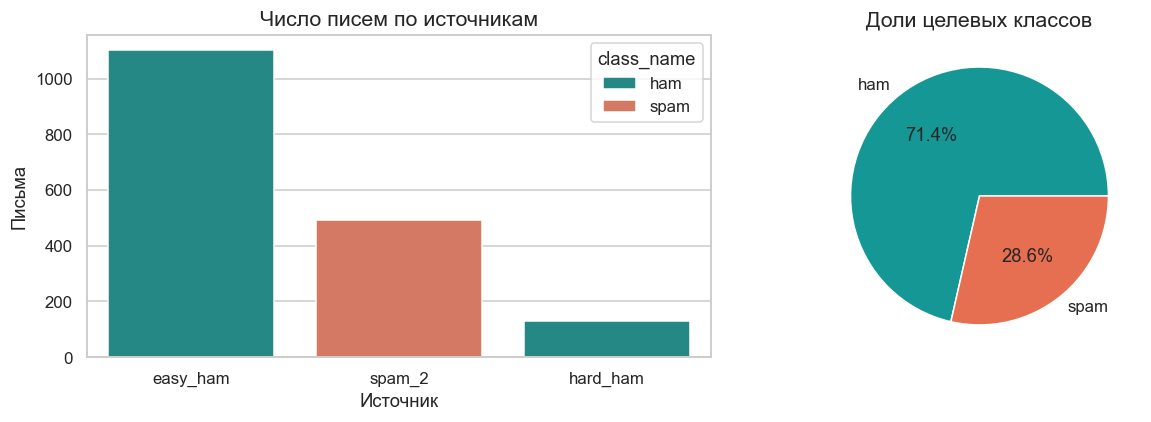

**Вывод.** В train доля обычных писем — 71.4%, доля `hard_ham` — 7.6%. Общая accuracy не отражает приоритет сохранения полезной почты. Для `hard_ham` отдельно анализируем FP/FPR; небольшой размер этого набора ограничивает точность оценки.

In [7]:
display(source_table(train))
plot_balance(train, FIGURES)
ham_share = train.label.eq(0).mean()
hard_ham_share = train.source.eq('hard_ham').mean()
display(Markdown(
    f'**Вывод.** В train доля обычных писем — {ham_share:.1%}, '
    f'доля `hard_ham` — {hard_ham_share:.1%}. '
    'Общая accuracy не отражает приоритет сохранения полезной почты. '
    'Для `hard_ham` отдельно анализируем FP/FPR; небольшой размер этого набора ограничивает точность оценки.'
))


## 2.2 Длина текста, пропуски и выбросы

Сравним число слов и символов. Логарифмическая шкала позволяет видеть распределение
при наличии очень длинных писем. Границы IQR считаем отдельно по каждому источнику.
Выброс по длине не означает ошибку разметки, поэтому автоматически такие письма не удаляем.


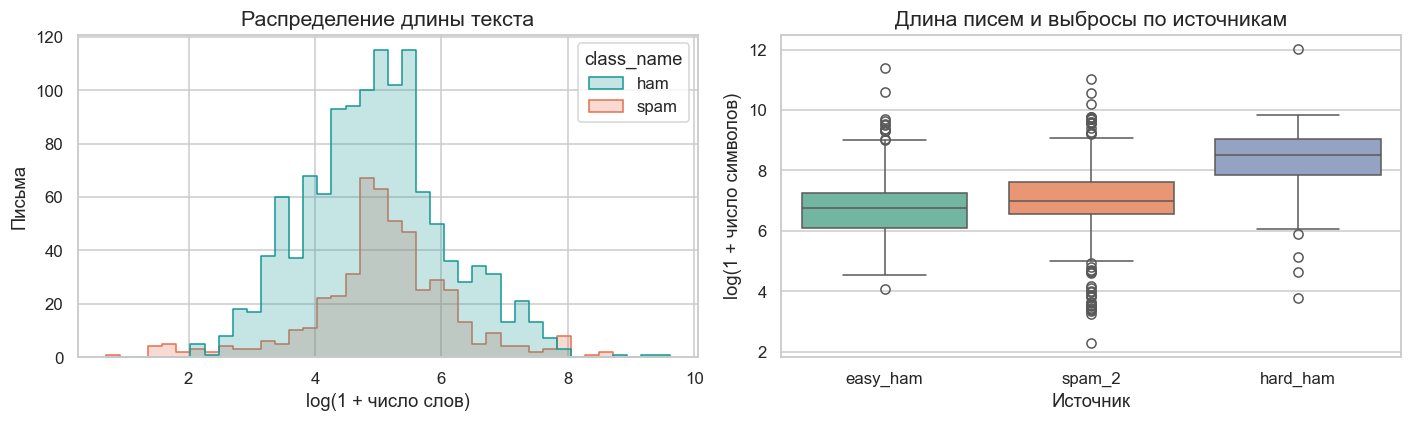

,q25,median,q75,q95,q99,upper_iqr,above_iqr
source,,,,,,,
easy_ham,61.0,126.0,225.0,612.9,1403.6,471.0,81
hard_ham,396.5,777.0,1258.0,2058.5,2964.1,2550.2,3
spam_2,99.0,161.0,283.0,985.0,2750.4,559.0,46


**Вывод.** Медианы числа слов по источникам: easy_ham: 126, hard_ham: 777, spam_2: 161. Используем TF-IDF с sublinear_tf: повторения одного слова не должны полностью определять решение.

In [8]:
plot_lengths(train, FIGURES)
length_table = train.groupby('source').n_words.quantile([0.25, 0.5, 0.75, 0.95, 0.99]).unstack()
length_table.columns = ['q25', 'median', 'q75', 'q95', 'q99']
length_table['upper_iqr'] = length_table.q75 + 1.5 * (length_table.q75 - length_table.q25)
length_table['above_iqr'] = [int((train.loc[train.source.eq(s), 'n_words'] > row.upper_iqr).sum()) for s, row in length_table.iterrows()]
display(length_table.round(1))
display(Markdown(
    '**Вывод.** Медианы числа слов по источникам: ' +
    ', '.join(f'{source}: {row["median"]:.0f}' for source, row in length_table.iterrows()) +
    '. Используем TF-IDF с sublinear_tf: повторения одного слова не должны полностью определять решение.'
))


## 2.3 HTML, вложения, ссылки и стиль текста

Проверим гипотезу, что HTML и ссылки сами по себе не являются достаточными признаками спама.
Особенно важен `hard_ham`: это полезные письма, которые внешне похожи на спам.
Число URL — описательная оценка в plain-тексте и HTML, включая альтернативное представление;
оно не означает число уникальных ссылок и не используется как самостоятельное правило блокировки.


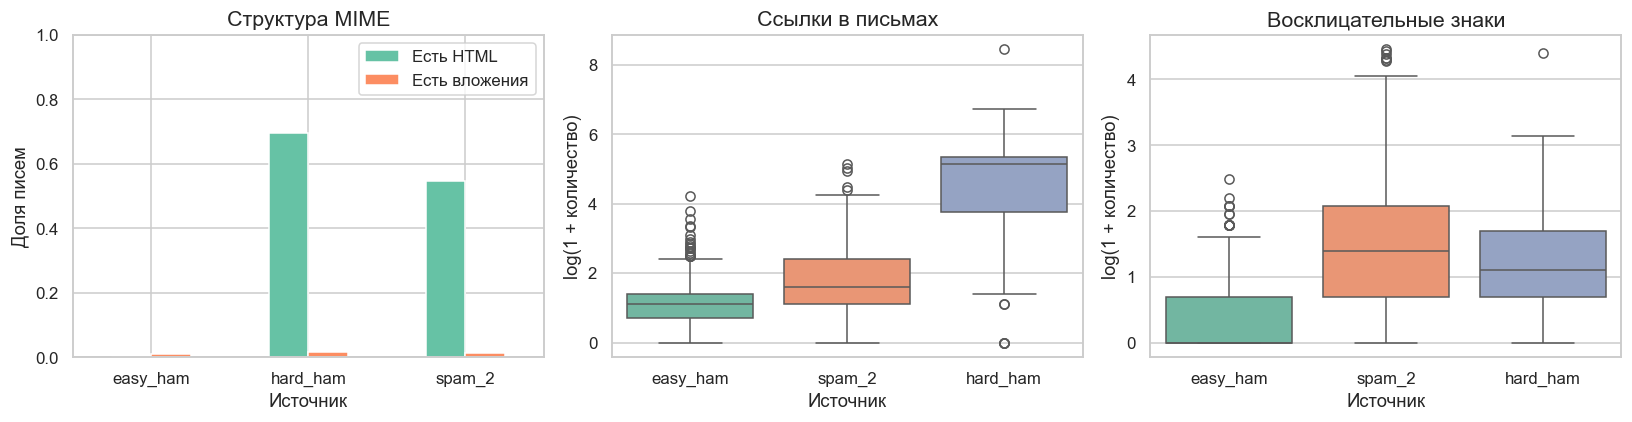

,html,n_urls,n_exclamations,uppercase_ratio,digit_ratio
source,,,,,
easy_ham,0.004,2.594,0.515,0.063,0.036
hard_ham,0.695,182.015,4.389,0.101,0.026
spam_2,0.546,9.223,6.420,0.145,0.028


**Вывод.** Доля HTML по источникам: easy_ham: 0.4%, hard_ham: 69.5%, spam_2: 54.6%. Наличие HTML оцениваем вместе с текстовым содержанием; отдельная блокировка HTML-писем создаёт риск FP.

In [9]:
plot_structure(train, FIGURES)
style_table = train.groupby('source')[['html', 'n_urls', 'n_exclamations', 'uppercase_ratio', 'digit_ratio']].mean()
display(style_table.round(3))
display(Markdown(
    '**Вывод.** Доля HTML по источникам: ' +
    ', '.join(f'{source}: {row.html:.1%}' for source, row in style_table.iterrows()) +
    '. Наличие HTML оцениваем вместе с текстовым содержанием; отдельная блокировка HTML-писем создаёт риск FP.'
))


## 2.4 Парные распределения признаков

Как в `PROJECT_final`, используем `pairplot`, но для характеристик писем.
На графике одинаковое число представителей каждого класса (до 180), поэтому он не отражает исходные доли классов.
Пересечение облаков точек показывает ограничения классификации по простым численным признакам.


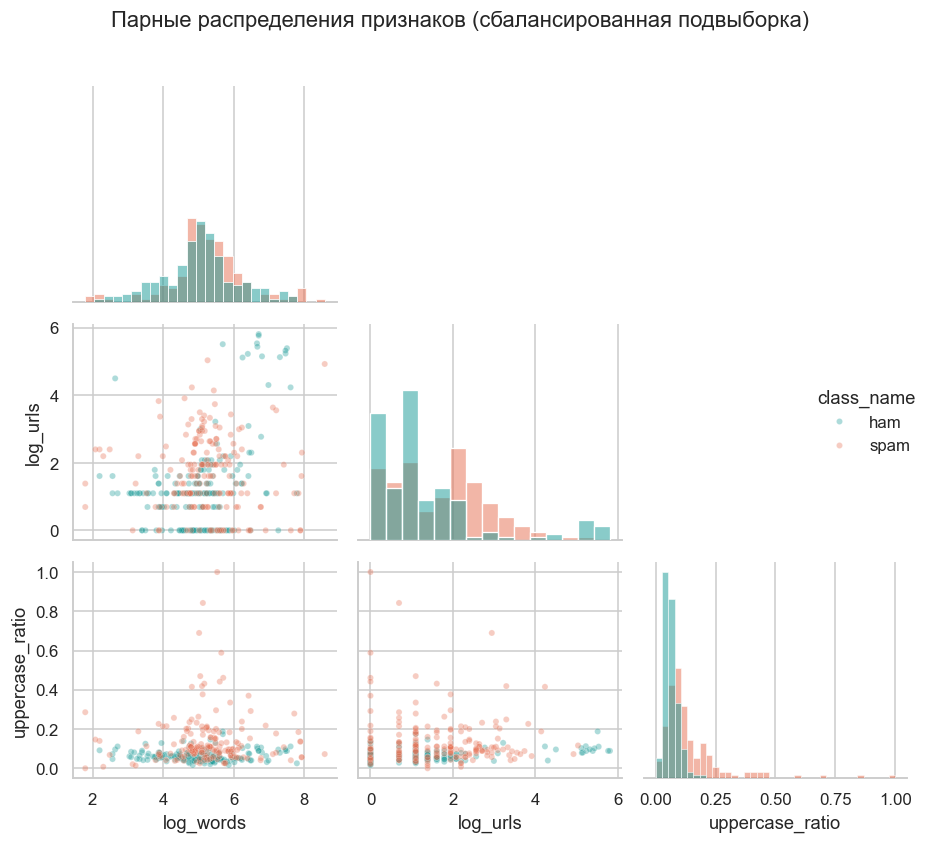

In [10]:
plot_pairs(train, FIGURES)


## 2.5 Корреляционный анализ

Используем корреляцию Спирмена: длины и счётчики имеют асимметричные распределения.
Корреляция с меткой — исследовательская характеристика конкретного корпуса, а не причинная связь.
Сильная корреляция числа слов и символов ожидаема: они описывают одну характеристику — длину.


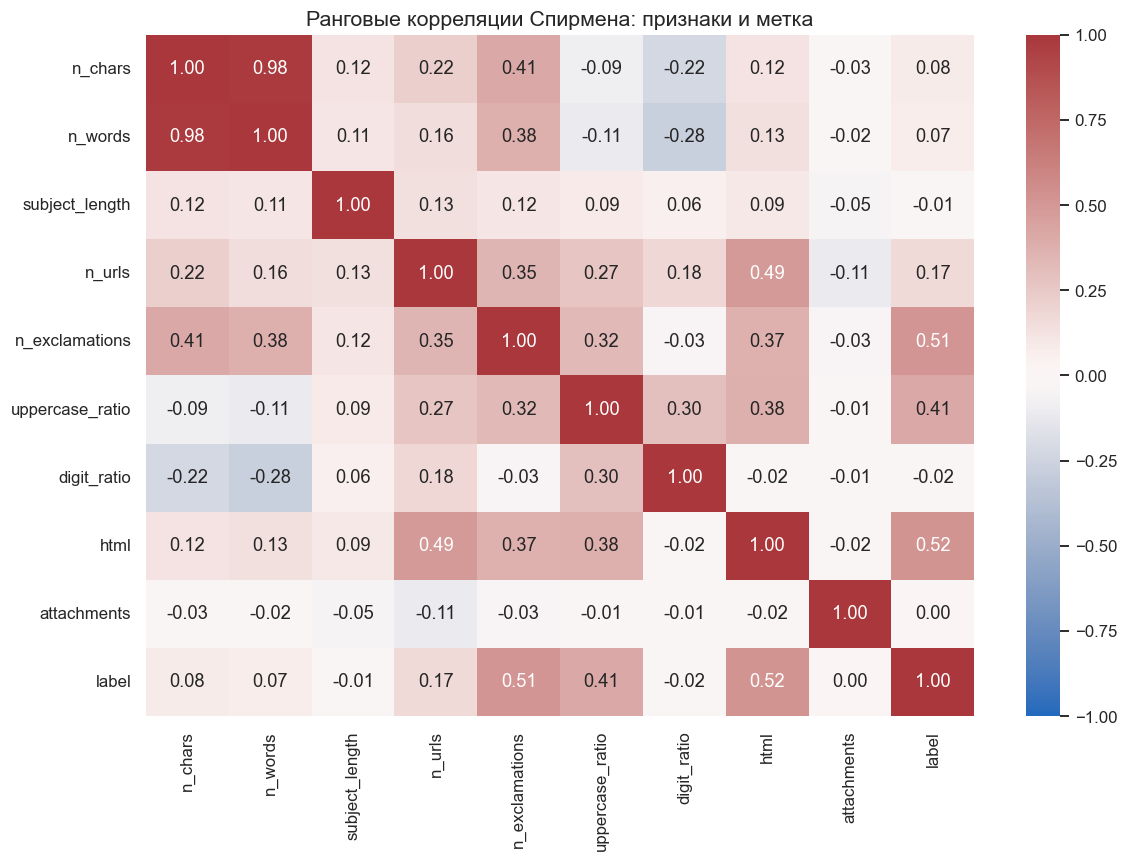

,spearman_with_label
html,0.518871
n_exclamations,0.511813
uppercase_ratio,0.410711
n_urls,0.166858
n_chars,0.084065
n_words,0.072176
digit_ratio,-0.015222
subject_length,-0.012867
attachments,0.003604


In [11]:
correlations = plot_correlations(train, FIGURES)
display(correlations['label'].drop('label').sort_values(key=abs, ascending=False).to_frame('spearman_with_label'))


## 2.6 Лексика ham и spam

Для каждого класса покажем слова с наибольшей разницей долей документов, содержащих слово.
Один длинный текст с многократным повторением слова учитывается один раз.
Английские stop words удаляются только для этого графика; обучаемый TF-IDF не использует этот список.
Словарь для EDA строится только по train и не передаётся классификаторам.


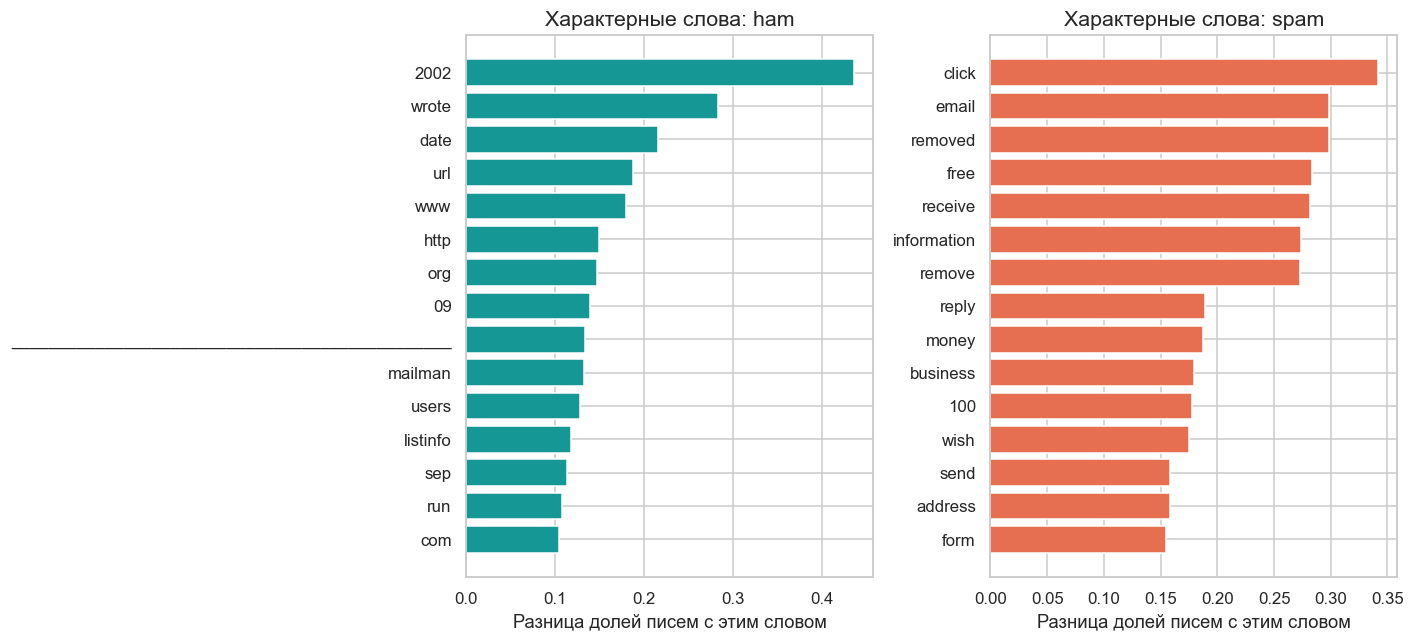

,class,term,document_share_difference
10,ham,www,0.179906
11,ham,url,0.188141
12,ham,date,0.216116
13,ham,wrote,0.283859
14,ham,2002,0.435887
25,spam,receive,0.281959
26,spam,free,0.283234
27,spam,removed,0.298186
28,spam,email,0.298658
29,spam,click,0.341657


**Вывод.** Характерные слова связаны как с типом сообщения, так и с тематикой рассылок. Такие признаки помогают на историческом корпусе, но могут ухудшить перенос на современную почту. В модель не передаются названия исходных каталогов.

In [12]:
word_table = plot_words(train, FIGURES)
word_table.to_csv(PROJECT_ROOT / 'reports/characteristic_words.csv', index=False)
display(word_table.groupby('class').tail(5))
display(Markdown(
    '**Вывод.** Характерные слова связаны как с типом сообщения, так и с тематикой рассылок. '
    'Такие признаки помогают на историческом корпусе, но могут ухудшить перенос на современную почту. '
    'В модель не передаются названия исходных каталогов.'
))


## 2.7 Проверка статистических гипотез

Нулевая гипотеза Манна–Уитни: распределения исследуемого признака в ham и spam одинаковы.
Для HTML проверяем независимость с классом χ²-тестом. Уровень значимости 0.05,
поправка Холма учитывает четыре проверки. Дополнительно показываем размеры эффектов:
rank-biserial для количественных признаков и Cramér's V для HTML.

Письма из рассылок могут быть зависимы; p-value здесь — исследовательский ориентир.
Статистическая значимость не доказывает высокое качество классификации и не заменяет тестовые метрики.


In [13]:
statistics = statistical_checks(train)
statistics.to_csv(PROJECT_ROOT / 'reports/statistical_checks.csv', index=False)
display(statistics)
significant = statistics.loc[statistics.significant_005, 'feature'].tolist()
display(Markdown(
    '**Вывод.** После поправки Холма различия обнаружены для: ' +
    (', '.join(significant) if significant else 'ни одного из проверенных признаков') +
    '. Для модели выбираем текстовые признаки, сохраняющие больше информации, чем отдельные счётчики.'
))


,feature,test,p_value,rank_biserial_ham_minus_spam,ham_median,spam_median,cramers_v,p_holm,significant_005
0,html,Chi-square,4.591650e-103,NaN,NaN,NaN,0.518871,1.836660e-102,True
1,uppercase_ratio,Mann–Whitney U,3.045254e-65,-0.524942,0.059398,0.104433,NaN,9.135762e-65,True
2,n_urls,Mann–Whitney U,4.205639e-12,-0.210853,2.000000,4.000000,NaN,8.411277e-12,True
3,n_words,Mann–Whitney U,2.720672e-03,-0.092250,141.000000,161.000000,NaN,2.720672e-03,True


**Вывод.** После поправки Холма различия обнаружены для: html, uppercase_ratio, n_urls, n_words. Для модели выбираем текстовые признаки, сохраняющие больше информации, чем отдельные счётчики.

## 2.8 Выводы по EDA и план моделирования

- Сохраняем `hard_ham` при стратификации и отдельно проверяем его FPR.
- Не удаляем длинные письма и HTML как выбросы: это могло бы искусственно упростить задачу.
- Применяем TF-IDF со словами и биграммами, `sublinear_tf=True`, ограничением словаря 30 000.
- Пропуски темы допустимы, пустой текст исключается из основного набора и остаётся в аудите.
- Подробный EDA не затрагивает отложенные тестовые выборки.

Большое число пересечений с контролем подтверждает необходимость проверки идентичности до обучения.
Глобальная дедупликация выполнена до разбиения; TF-IDF обучается только внутри соответствующего train-фолда.


<a id="modeling"></a>
# 3. Обучение и кросс-валидация

## 3.1 Выбор архитектур и baseline

| Модель | Роль в эксперименте |
|---|---|
| Dummy: always ham | Сохраняет всю обычную почту, но не находит спам; показывает, почему одного FPR недостаточно |
| ComplementNB, α = 0.5 / 1.0 | Быстрый текстовый baseline, сравнение сглаживания |
| LogisticRegression, C = 0.5 / 2.0 | Линейная модель на разреженном TF-IDF; вес ham вдвое выше |
| LinearSVC, C = 1.0 | Линейный SVM; хорошо подходит для большого числа разреженных признаков |

Для корпуса такого размера линейные модели позволяют быстро сравнить несколько вариантов
без скачивания трансформеров. Бустинг не обязателен по заданию; выбранные модели работают
непосредственно с разреженными векторами TF-IDF. Числовые признаки EDA не используются при обучении.

Каждая конфигурация проходит 5-fold CV внутри train. Сначала предпочитаем модели со средними
Precision ≥ 0.99 и FPR ≤ 0.01, затем максимизируем средний F0.5, далее учитываем FPR и Recall.
Если ограничения на CV недостижимы, выбираем лучший F0.5 и явно сохраняем этот факт в таблице.
Средние по фолдам — сравнение моделей, а не несмещённая итоговая оценка выбранного победителя.


In [14]:
# train_experiment: CV → fit на train → порог на validation → фиксированная оценка.
# Одни и те же функции вызываются из ноутбука и build.py.
experiment = train_experiment(prepared, report_dir=PROJECT_ROOT / 'reports')
model = experiment['model']
summary = experiment['summary']
cv_table = experiment['cv_table']
threshold = float(summary['threshold']['threshold'])
display(cv_table)
display(Markdown(f'**Выбрана модель:** {summary["selected_model"]}.'))


CV (5 folds): Dummy: always ham


CV (5 folds): ComplementNB alpha=0.5


CV (5 folds): ComplementNB alpha=1.0


CV (5 folds): LogisticRegression C=0.5


CV (5 folds): LogisticRegression C=2.0


CV (5 folds): LinearSVC C=1.0


,model,fit_seconds_mean,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,f05_mean,f05_std,fpr_mean,fpr_std,cv_constraints_met
0,ComplementNB alpha=1.0,1.532998,0.997500,0.005590,0.851989,0.035860,0.918761,0.023044,0.964360,0.013044,0.000813,0.001818,True
1,LogisticRegression C=2.0,1.476831,0.990030,0.010358,0.823624,0.040535,0.898879,0.027111,0.951342,0.016971,0.003239,0.003378,True
2,LogisticRegression C=0.5,1.732821,1.000000,0.000000,0.563966,0.028971,0.720842,0.024127,0.865674,0.014173,0.000000,0.000000,True
3,LinearSVC C=1.0,1.387861,0.980946,0.008612,0.939270,0.033362,0.959418,0.018642,0.972159,0.010748,0.007294,0.003370,False
4,ComplementNB alpha=0.5,1.357168,0.981057,0.015213,0.931066,0.027091,0.955150,0.013947,0.970461,0.011706,0.007291,0.005981,False
5,Dummy: always ham,1.497362,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,False


**Выбрана модель:** ComplementNB alpha=1.0.

## 3.2 Сравнение моделей на кросс-валидации

Сравниваем среднее качество и разброс между фолдами при стандартном пороге каждой модели.
TF-IDF включён в Pipeline и заново обучается на каждом фолде: словарь и IDF проверочного фолда
не используются при обучении. Параметры кандидатов зафиксированы до просмотра тестовых результатов.


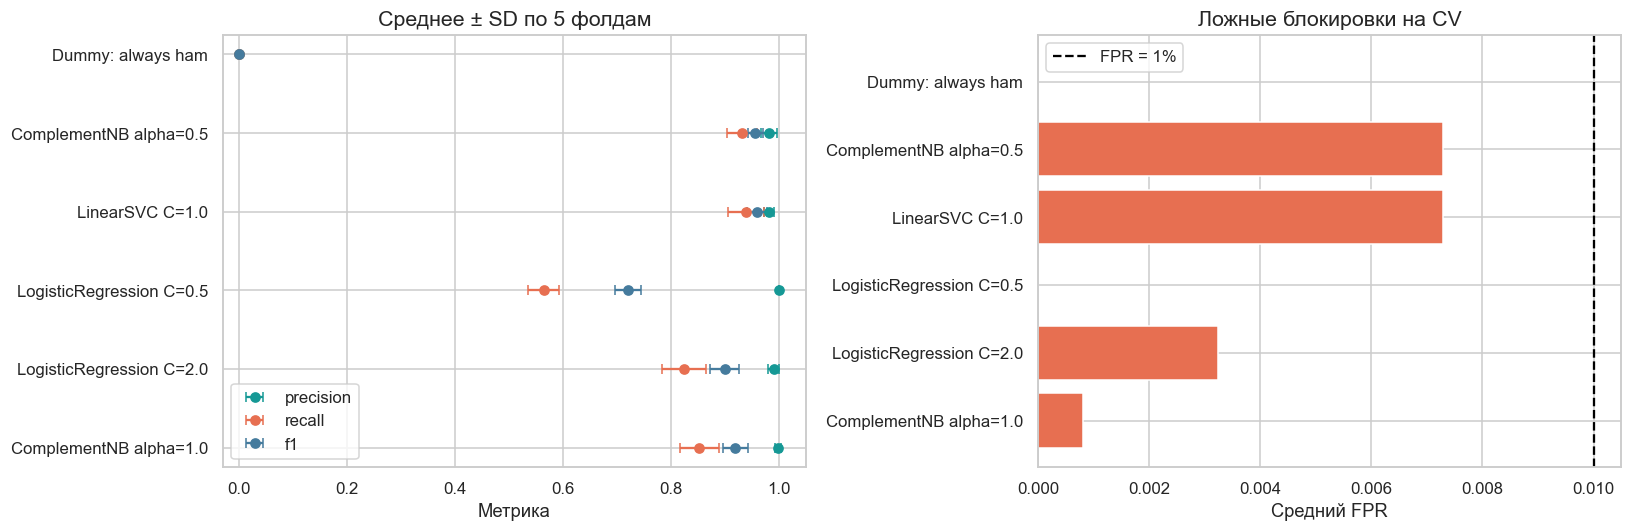

,model,fold,precision,recall,f1,f05,fpr
0,Dummy: always ham,1,0.000000,0.000000,0.000000,0.000000,0.000000
1,Dummy: always ham,2,0.000000,0.000000,0.000000,0.000000,0.000000
2,Dummy: always ham,3,0.000000,0.000000,0.000000,0.000000,0.000000
3,Dummy: always ham,4,0.000000,0.000000,0.000000,0.000000,0.000000
4,Dummy: always ham,5,0.000000,0.000000,0.000000,0.000000,0.000000
5,ComplementNB alpha=0.5,1,0.959184,0.959184,0.959184,0.959184,0.016129
6,ComplementNB alpha=0.5,2,1.000000,0.918367,0.957447,0.982533,0.000000
7,ComplementNB alpha=0.5,3,0.978495,0.919192,0.947917,0.966030,0.008130
8,ComplementNB alpha=0.5,4,0.978022,0.898990,0.936842,0.961123,0.008130
9,ComplementNB alpha=0.5,5,0.989583,0.959596,0.974359,0.983437,0.004065


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for metric, color in [('precision', '#159895'), ('recall', '#e76f51'), ('f1', '#457b9d')]:
    axes[0].errorbar(cv_table[metric + '_mean'], np.arange(len(cv_table)),
                     xerr=cv_table[metric + '_std'], fmt='o', capsize=3, label=metric, color=color)
axes[0].set_yticks(np.arange(len(cv_table)), cv_table.model)
axes[0].set(xlim=(-0.03, 1.05), title='Среднее ± SD по 5 фолдам', xlabel='Метрика')
axes[0].legend()
axes[1].barh(cv_table.model, cv_table.fpr_mean, color='#e76f51')
axes[1].axvline(MAX_FPR, color='black', linestyle='--', label='FPR = 1%')
axes[1].set(title='Ложные блокировки на CV', xlabel='Средний FPR')
axes[1].legend()
finish_figure(fig, FIGURES, '07_cv_comparison')
display(experiment['cv_folds'])


## 3.3 Подбор порога с приоритетом обычной почты

Стандартный порог — 0.5 для моделей с `predict_proba` и 0 для `decision_function` SVC.
Оценки вероятности не считаем отдельно откалиброванными.
Рассматриваем середины интервалов между уникальными оценками на validation, плюс крайние решения.

Из порогов с Precision ≥ 0.99, FPR ≤ 0.01 и найденным спамом выбираем минимум FP,
затем максимум Recall. Если допустимого порога нет, сохраняем явный статус отказа и
решение «всё ham», которое не считается успешным антиспамом.

Такой выбор порога согласуется с [руководством scikit-learn](https://scikit-learn.org/stable/modules/classification_threshold.html):
порог нужно настраивать на данных, не использованных при fit. Здесь это validation.


,Выбранный порог
threshold,0.862981
precision,1.0
recall,0.615854
fpr,0.0
fp,0
tp,101
f05,0.889085
constraints_met,True
selection_status,constraints_met_on_validation


,threshold,precision,recall,fpr,fp,tp,f05,constraints_met
475,0.862981,1.0,0.615854,0.0,0,101,0.889085,True
476,0.863618,1.0,0.609756,0.0,0,100,0.886525,True
477,0.871324,1.0,0.603659,0.0,0,99,0.883929,True
478,0.880663,1.0,0.597561,0.0,0,98,0.881295,True
479,0.882587,1.0,0.591463,0.0,0,97,0.878623,True
480,0.884831,1.0,0.585366,0.0,0,96,0.875912,True
481,0.887782,1.0,0.579268,0.0,0,95,0.873162,True
482,0.889704,1.0,0.573171,0.0,0,94,0.870370,True
483,0.890898,1.0,0.567073,0.0,0,93,0.867537,True
484,0.893015,1.0,0.560976,0.0,0,92,0.864662,True


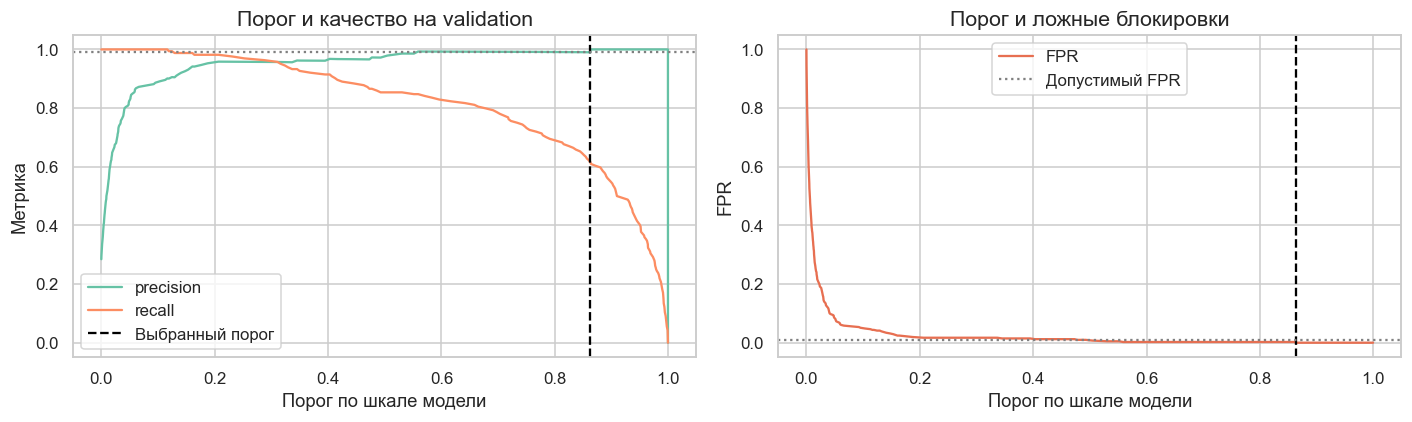

In [16]:
threshold_info = summary['threshold']
display(pd.Series(threshold_info, name='Выбранный порог').to_frame())
search = experiment['threshold_table']
display(search.loc[search.constraints_met].sort_values(['fp', 'recall'], ascending=[True, False]).head(10))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for metric in ['precision', 'recall']:
    axes[0].plot(search.threshold, search[metric], label=metric)
axes[0].axvline(threshold, color='black', linestyle='--', label='Выбранный порог')
axes[0].axhline(TARGET_PRECISION, color='gray', linestyle=':')
axes[0].set(title='Порог и качество на validation', xlabel='Порог по шкале модели', ylabel='Метрика')
axes[0].legend()
axes[1].plot(search.threshold, search.fpr, color='#e76f51', label='FPR')
axes[1].axvline(threshold, color='black', linestyle='--')
axes[1].axhline(MAX_FPR, color='gray', linestyle=':', label='Допустимый FPR')
axes[1].set(title='Порог и ложные блокировки', xlabel='Порог по шкале модели', ylabel='FPR')
axes[1].legend()
finish_figure(fig, FIGURES, '08_threshold_selection')


<a id="evaluation"></a>
# 4. Контрольный тест и анализ ошибок

## 4.1 Метрики на отложенных данных

Показываем стандартный и выбранный пороги. После этой оценки модель и порог не меняются.
`external_all` содержит весь читаемый контрольный архив, включая повторы и пустой текст;
`external_unique` — основной очищенный контроль без повторов, пустого текста и конфликтующих меток.
Разницу размеров фиксируем в аудите, результаты полного набора также сохраняем.
Внешние метрики не используются для выбора модели, параметров или порога.


In [17]:
metric_rows = []
for dataset, metrics in summary['evaluations'].items():
    for policy_name, values in [('standard', metrics['default_threshold_metrics']), ('selected', metrics)]:
        metric_rows.append({'dataset': dataset, 'policy': policy_name, **{
            key: values[key] for key in ['n', 'precision', 'recall', 'f1', 'f05', 'fpr', 'fp', 'fn', 'fpr_upper_95']
        }})
metric_table = pd.DataFrame(metric_rows)
metric_table.to_csv(PROJECT_ROOT / 'reports/final_comparison.csv', index=False)
display(metric_table.round(5))
display(Markdown(
    '**Вывод.** Выбранный порог контролирует риск по validation. '
    'Выполнение ограничений на test и внешнем контроле оцениваем по фактическим метрикам; '
    'никаких гарантий по ним заранее нет.'
))


,dataset,policy,n,precision,recall,f1,f05,fpr,fp,fn,fpr_upper_95
0,validation,standard,576,0.97902,0.85366,0.91205,0.95109,0.00728,3,24,0.01871
1,validation,selected,576,1.00000,0.61585,0.76226,0.88908,0.00000,0,63,0.00724
2,test,standard,576,0.97959,0.87805,0.92605,0.95745,0.00728,3,20,0.01871
3,test,selected,576,1.00000,0.62805,0.77154,0.89410,0.00000,0,61,0.00724
4,external_unique,standard,1493,0.99591,0.80842,0.89242,0.95176,0.00508,3,173,0.01309
5,external_unique,selected,1493,1.00000,0.38870,0.55981,0.76073,0.00000,0,552,0.00506
6,external_all,standard,1600,0.99632,0.81200,0.89477,0.95305,0.00500,3,188,0.01287
7,external_all,selected,1600,1.00000,0.39100,0.56219,0.76248,0.00000,0,609,0.00498


**Вывод.** Выбранный порог контролирует риск по validation. Выполнение ограничений на test и внешнем контроле оцениваем по фактическим метрикам; никаких гарантий по ним заранее нет.

## 4.2 Матрицы ошибок

Строки — истинный класс, столбцы — предсказание. Верхний правый элемент — FP:
полезное письмо ошибочно признано спамом. Нижний левый — пропущенный спам.


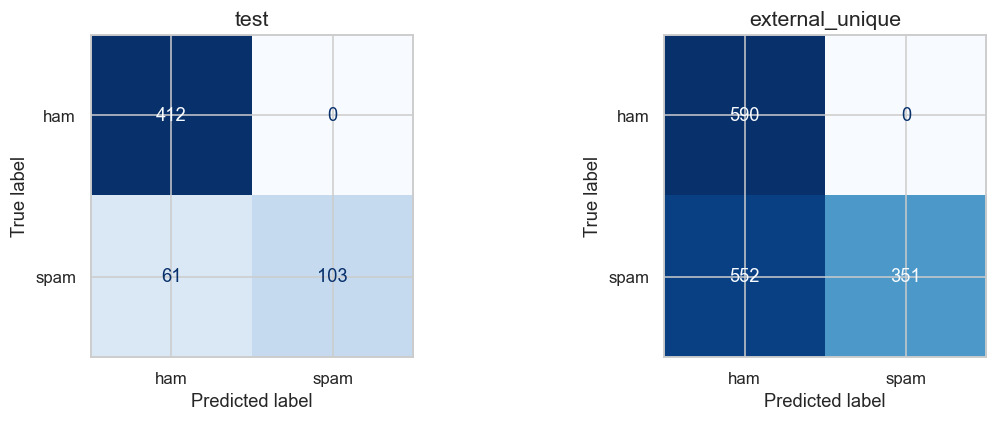

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for dataset, ax in zip(['test', 'external_unique'], axes):
    predictions = experiment['predictions'][dataset]
    ConfusionMatrixDisplay.from_predictions(predictions.label, predictions.prediction,
        labels=[0, 1], display_labels=['ham', 'spam'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(dataset)
finish_figure(fig, FIGURES, '09_confusion_matrices')


## 4.3 Precision–Recall и ROC

Эти кривые характеризуют ранжирование и показаны для итоговой диагностики.
PR-кривая особенно полезна при изменении доли спама. Рабочую точку после просмотра кривых не меняем.


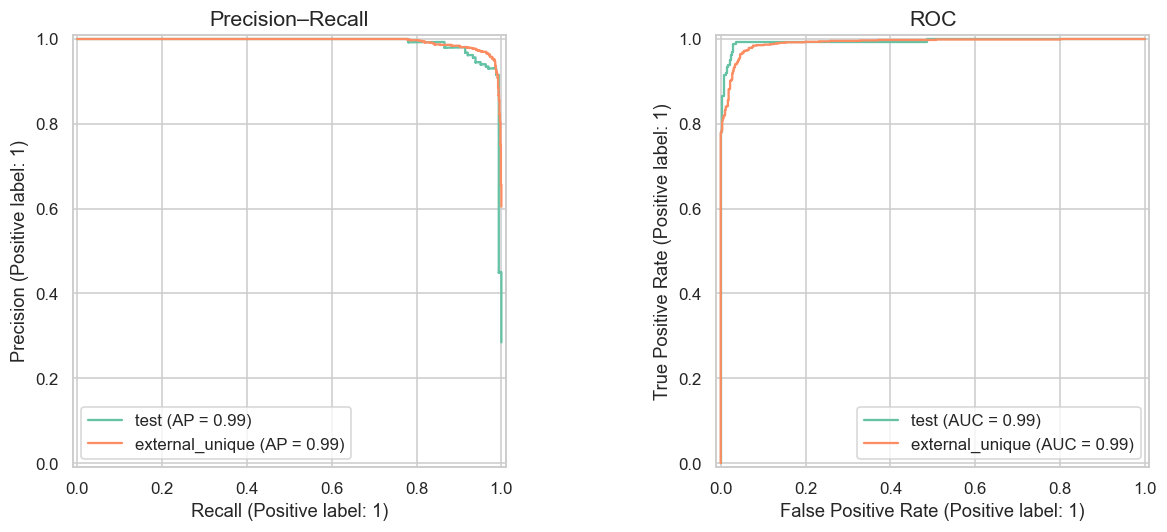

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for dataset in ['test', 'external_unique']:
    predictions = experiment['predictions'][dataset]
    PrecisionRecallDisplay.from_predictions(predictions.label, predictions.score, name=dataset, ax=axes[0])
    RocCurveDisplay.from_predictions(predictions.label, predictions.score, name=dataset, ax=axes[1])
axes[0].set_title('Precision–Recall')
axes[1].set_title('ROC')
finish_figure(fig, FIGURES, '10_pr_roc')


## 4.4 Отдельная проверка hard_ham и разбор ошибок

Для источника, содержащего только ham, основная метрика — FPR; Precision/Recall спама
в такой подвыборке не содержательны и не интерпретируются. Сравниваем число FP и объём ham.
Тесты не переобучаем и ручные исключения по найденным ошибкам не добавляем.


In [20]:
source_metrics = experiment['by_source']['test']
display(source_metrics[['source', 'n', 'ham', 'spam', 'fp', 'fn', 'fpr', 'fpr_upper_95']])
for dataset in ['test', 'external_unique']:
    predictions = experiment['predictions'][dataset]
    errors = predictions.loc[predictions.error_type.ne('correct')]
    display(Markdown(f'**{dataset}: {len(errors)} ошибок.** Примеры (тема, без служебных заголовков):'))
    display(errors[['source', 'label', 'prediction', 'score', 'error_type', 'subject']].head(12))
    display(predictions.groupby(['source', 'error_type']).size().rename('emails').to_frame())


,source,n,ham,spam,fp,fn,fpr,fpr_upper_95
0,easy_ham,368,368,0,0,0,0.0,0.008108
1,hard_ham,44,44,0,0,0,0.0,0.065819
2,spam_2,164,0,164,0,61,0.0,NaN


**test: 61 ошибок.** Примеры (тема, без служебных заголовков):

,source,label,prediction,score,error_type,subject
13,spam_2,1,0,0.860706,false_negative,Hi-Mind:Opt-in referencement
16,spam_2,1,0,0.283614,false_negative,Re: Your Online Prescription Source N
30,spam_2,1,0,0.813868,false_negative,[ILUG-Social] Mortgage Rates Are Down. isoxtjcn
33,spam_2,1,0,0.857623,false_negative,Weight Loss Secrets Of Doctors And Famous Stars!!.....
45,spam_2,1,0,0.758883,false_negative,Call me on My Telephone Number 234-80-33357110
69,spam_2,1,0,0.248007,false_negative,[����]��ǰ���&��ǰȭ��ǰ
76,spam_2,1,0,0.628277,false_negative,Keep your private life private. EZ Internet Privacy
95,spam_2,1,0,0.556602,false_negative,Traderlist.com being shut down due to FRAUD!
99,spam_2,1,0,0.354685,false_negative,[SA] Chuong trinh khuyen mai he 2002
104,spam_2,1,0,0.448101,false_negative,�{�i���򰸹��G Life-Time upgrades for FREE guarantees6s2n2k6


emails
source   error_type            
easy_ham correct            368
hard_ham correct             44
spam_2   correct            103
         false_negative      61

**external_unique: 552 ошибок.** Примеры (тема, без служебных заголовков):

,source,label,prediction,score,error_type,subject
590,spam,1,0,0.852755,false_negative,Attention! Your PayPal account has been violated!
594,spam,1,0,0.435474,false_negative,Lease Deal
595,spam,1,0,0.602406,false_negative,Account Review Department
599,spam,1,0,0.573988,false_negative,Increase Length And Thickness OCW
601,spam,1,0,0.395773,false_negative,good friend nUYiIFa3s19FyqZIEEC3lLvT
606,spam,1,0,0.674688,false_negative,Regions Bank corporate customer cervice: secure details confirmation! (message id: L04...
607,spam,1,0,0.277088,false_negative,adv: Put your resume back to work
608,spam,1,0,0.590986,false_negative,[ILUG] BUSINESS
609,spam,1,0,0.385012,false_negative,"re:想要致富,你還要等多久"
610,spam,1,0,0.789844,false_negative,North Fork Bank reminder: confirm your account details!


emails
source error_type            
ham    correct            590
spam   correct            351
       false_negative     552

## 4.5 Неопределённость ложноположительных срабатываний

Нулевое число FP не означает нулевую вероятность ошибки. Для FPR вычислена односторонняя
верхняя 95%-граница точного интервала Clopper–Pearson. Например, при 0 FP из 100 ham
она составляет примерно 3%. Это интервал для фиксированного классификатора при независимых
наблюдениях; сообщения из одной рассылки могут нарушать эту предпосылку.
На validation граница дополнительно смещена адаптивным выбором порога, поэтому ориентируемся на test/контроль.


In [21]:
uncertainty = metric_table.loc[(metric_table.policy == 'selected') & metric_table.dataset.ne('validation'),
    ['dataset', 'n', 'fp', 'fpr', 'fpr_upper_95']]
display(uncertainty)
for dataset in ['test', 'external_unique']:
    values = summary['evaluations'][dataset]
    display(Markdown(
        f'**{dataset}:** FP = {values["fp"]} из {values["ham"]} ham; '
        f'наблюдаемый FPR = {values["fpr"]:.2%}, верхняя 95%-граница = {values["fpr_upper_95"]:.2%}.'
    ))


,dataset,n,fp,fpr,fpr_upper_95
3,test,576,0,0.0,0.007245
5,external_unique,1493,0,0.0,0.005065
7,external_all,1600,0,0.0,0.004980


**test:** FP = 0 из 412 ham; наблюдаемый FPR = 0.00%, верхняя 95%-граница = 0.72%.

**external_unique:** FP = 0 из 590 ham; наблюдаемый FPR = 0.00%, верхняя 95%-граница = 0.51%.

## 4.6 Пример использования обученной модели в памяти

Это локальный вызов модели, без сервера, контейнера и сериализации.
Демонстрационные тексты не являются дополнительной оценкой качества.


In [22]:
from email.message import EmailMessage

examples = []
for subject, body in [
    ('Team meeting', 'Please review the meeting agenda and project report before Monday.'),
    ('Congratulations! Claim your prize', 'WIN cash now! Click here to claim your FREE prize and special offer.'),
]:
    message = EmailMessage()
    message['Subject'] = subject
    message.set_content(body)
    parsed = parse_email(message.as_bytes())
    score = float(spam_scores(model, [parsed['text']])[0])
    examples.append({'subject': subject, 'score': score, 'threshold': threshold,
                     'prediction': 'spam' if score >= threshold else 'ham'})
display(pd.DataFrame(examples))


,subject,score,threshold,prediction
0,Team meeting,0.325058,0.862981,ham
1,Congratulations! Claim your prize,0.906304,0.862981,spam


<a id="results"></a>
# 5. Результаты, ограничения и воспроизводимость

## 5.1 Итоги эксперимента


In [23]:
internal = summary['evaluations']['test']
control = summary['evaluations']['external_unique']
full_control = summary['evaluations']['external_all']
status = 'выполнены' if control['precision'] >= TARGET_PRECISION and control['fpr'] <= MAX_FPR else 'не выполнены'
display(Markdown(f'''
**Этап 1 выполнен:** из {len(raw):,} писем исходных корпусов подготовлено {len(prepared.clean):,}
непересекающихся с внешним контролем уникальных писем. Размеры train/validation/test:
{len(train):,}/{len(validation):,}/{len(test):,}. Исходные файлы и причины исключений сохранены.

**Этап 2 выполнен:** сравнены шесть конфигураций на {CV_FOLDS}-fold CV; выбрана
**{summary['selected_model']}**, порог **{threshold:.6f}**. Статус выбора порога:
`{summary['threshold']['selection_status']}`.

| Выборка | Precision | Recall | F1 | FP | FPR |
|---|---:|---:|---:|---:|---:|
| Внутренний test | {internal['precision']:.4f} | {internal['recall']:.4f} | {internal['f1']:.4f} | {internal['fp']} | {internal['fpr']:.4%} |
| Внешний контроль, уникальные | {control['precision']:.4f} | {control['recall']:.4f} | {control['f1']:.4f} | {control['fp']} | {control['fpr']:.4%} |
| Внешний контроль, полный | {full_control['precision']:.4f} | {full_control['recall']:.4f} | {full_control['f1']:.4f} | {full_control['fp']} | {full_control['fpr']:.4%} |

На очищенном внешнем контроле ограничения Precision ≥ {TARGET_PRECISION:.0%} и FPR ≤ {MAX_FPR:.0%}
**{status}**. Результат отражён фактически; внешние метрики не использованы для изменения решения.
'''))



**Этап 1 выполнен:** из 4,197 писем исходных корпусов подготовлено 2,878
непересекающихся с внешним контролем уникальных писем. Размеры train/validation/test:
1,726/576/576. Исходные файлы и причины исключений сохранены.

**Этап 2 выполнен:** сравнены шесть конфигураций на 5-fold CV; выбрана
**ComplementNB alpha=1.0**, порог **0.862981**. Статус выбора порога:
`constraints_met_on_validation`.

| Выборка | Precision | Recall | F1 | FP | FPR |
|---|---:|---:|---:|---:|---:|
| Внутренний test | 1.0000 | 0.6280 | 0.7715 | 0 | 0.0000% |
| Внешний контроль, уникальные | 1.0000 | 0.3887 | 0.5598 | 0 | 0.0000% |
| Внешний контроль, полный | 1.0000 | 0.3910 | 0.5622 | 0 | 0.0000% |

На очищенном внешнем контроле ограничения Precision ≥ 99% и FPR ≤ 1%
**выполнены**. Результат отражён фактически; внешние метрики не использованы для изменения решения.


## 5.2 Ограничения и дальнейшие шаги

- Корпуса исторические, преимущественно англоязычные. Проверка на современной русскоязычной почте не проведена.
- Три локальных набора относятся к SpamAssassin. Самостоятельные LingSpam/Enron/другие домены
  могут улучшить разнообразие, но должны добавляться с отдельной проверкой лицензий и дубликатов.
- Точная дедупликация не исключает близкие шаблоны, цитирование и зависимость писем внутри рассылок.
  Для строгой следующей итерации полезны группировка по цепочкам и временной контроль.
- Снижение FP обычно уменьшает Recall. Нельзя бесконечно повышать порог: классификатор «всё ham» бесполезен.
- После просмотра итогового контроля его нужно считать использованным: для новых решений потребуется свежий контроль.
- Для мультиязычности нужны размеченные письма разных языков и проверка метрик отдельно по языкам;
  возможна следующая итерация с символьными n-граммами или multilingual embeddings.
- Для concept drift нужны мониторинг FP по обратной связи, изменение распределений текста,
  версионирование данных и регулярное переобучение с новой независимой валидацией порога.
- При полуобучении нельзя автоматически считать все предсказания истинной разметкой:
  полезны ручная проверка спорных примеров и отдельная оценка подтверждённых меток.

Модель обучена в памяти текущего kernel. `build.py` заново обучает её, сохраняет обработанные данные,
метрики, предсказания, Pipeline и порог для сервиса. `export_model.py` восстанавливает выбранную модель
на сохранённом train и проверяет совпадение предсказаний без повторной настройки.
FastAPI и Docker описаны в разделе 6. Публичный хостинг и отправка презентации не выполнялись.


## 5.3 Как воспроизвести

Из папки `PROJECT_antispam`:

```text
python -m venv .venv
.venv\Scripts\python -m pip install -r requirements.txt
.venv\Scripts\python -m src.download_external
.venv\Scripts\python build.py
.venv\Scripts\python -m unittest discover -s tests -v
.venv\Scripts\python run_notebook.py
```

На Linux/macOS вместо `.venv\Scripts\python` используется `.venv/bin/python`.
`build.py` — программный ML-конвейер, `run_notebook.py` выполняет все ячейки и записывает готовый ноутбук.
`make_notebook.py` генерирует исходный ноутбук, стирая его результаты; для обычного запуска он не нужен.

Сохранены `data/processed/*.csv.gz`, аудит, параметры эксперимента, результаты CV,
поиск порога, предсказания, PNG-графики и итоговые метрики в `reports/`.
Фиксированы random state, разбиение, список моделей и зависимости.

Методические источники: [защита от утечки в scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html),
[настройка порога](https://scikit-learn.org/stable/modules/classification_threshold.html),
[описание SpamAssassin](https://spamassassin.apache.org/old/publiccorpus/readme.html).


<a id="packaging"></a>
# 6. Упаковка модели: FastAPI и Docker

## 6.1 Артефакт обученной модели

Сохраняются TF-IDF и классификатор как единый `Pipeline`, выбранный порог, тип оценки,
версии библиотек и SHA-256 файла. Сервис проверяет контрольную сумму, версии и согласованность
метаданных при запуске. Загружается только собственный локальный артефакт;
пользовательские файлы не десериализуются как модели.

`export_model.py` обучает уже выбранную конфигурацию только на сохранённом train и
проверяет точное совпадение решений и численное совпадение оценок на validation, test и внешнем контроле.
Параметры и порог по результатам упаковки не подбираются.


In [24]:
from src.artifacts import DEFAULT_MODEL_DIR, load_artifact, save_artifact

if not (DEFAULT_MODEL_DIR / 'model.joblib').exists():
    save_artifact(model, summary, DEFAULT_MODEL_DIR, train=train)
service_bundle, service_metadata = load_artifact(DEFAULT_MODEL_DIR)
np.testing.assert_allclose(
    spam_scores(service_bundle['pipeline'], test.text), spam_scores(model, test.text),
    rtol=1e-12, atol=1e-12,
)
assert service_bundle['threshold'] == threshold
display(pd.Series({key: service_metadata[key] for key in [
    'model_name', 'threshold', 'score_kind', 'training_rows', 'model_sha256', 'packages',
]}).to_frame('Артефакт сервиса'))
print('Экспортированная модель совпадает с моделью эксперимента.')


,Артефакт сервиса
model_name,ComplementNB alpha=1.0
threshold,0.862981
score_kind,probability_estimate
training_rows,1726
model_sha256,15078934f2829e97783f398ec11a1971469ce11ff56a1dade0eeef1e55777a2c
packages,"{'scikit-learn': '1.9.1', 'numpy': '2.3.5', 'scipy': '1.18.1', 'joblib': '1.6.0'}"


Экспортированная модель совпадает с моделью эксперимента.


## 6.2 HTTP-сервис и запуск контейнера

| Метод | Путь | Назначение |
|---|---|---|
| GET | `/health` | Состояние загруженной модели |
| GET | `/model` | Версия, порог и контрольная сумма модели |
| POST | `/predict` | JSON: `text` либо `subject`, `body`, `body_format` |
| POST | `/predict/eml` | Загрузка RFC 822/MIME `.eml` |
| GET | `/docs` | Swagger для интерактивной демонстрации |

Пример запроса:

```json
{"subject": "Team meeting", "body": "Please review the report before Monday."}
```

Ответ включает `label`, `is_spam`, `score`, `threshold`, `score_kind`, `model_name`.
JSON и `.eml` используют тот же парсер MIME/HTML, что и обучение.
Пустой текст возвращает HTTP 422; для `.eml` действует ограничение 2 МиБ (HTTP 413).
Обучение при HTTP-запросах не выполняется; модель загружается один раз при старте.

Из папки проекта в PowerShell:

```powershell
.\start_docker.ps1                  # сборка образа и запуск с ожиданием healthcheck
.\start_docker.ps1 -SkipBuild       # запуск готового образа
.\start_docker.ps1 -Port 8080       # другой порт
.\stop_docker.ps1                   # остановка контейнера проекта
```

Контейнер запускается пользователем без root-прав, содержит модель и зависимости инференса;
обучающие данные и ноутбук не копируются в образ. Swagger: `http://127.0.0.1:8000/docs`.
Подробности и команды проверки: `docs/DOCKER.md`.


In [2]:
verification_file = PROJECT_ROOT / 'reports/docker_api_verification.json'
if verification_file.exists():
    docker_verification = json.loads(verification_file.read_text(encoding='utf-8'))
    display(pd.DataFrame(docker_verification['prediction_checks']))
    display(Markdown(
        '**Этап 3 выполнен.** Docker-контейнер собран и проверен реальными HTTP-запросами: '
        'healthcheck, информация о модели, JSON, загрузка .eml и валидация входа. '
        'Предсказания контейнера совпали с сохранёнными результатами эксперимента. '
        'Это сохранённый отчёт проверки; текущее состояние контейнера проверяется через `/health`.'
    ))
else:
    display(Markdown('Конфигурация сервиса подготовлена. Для сохранения HTTP-проверки выполните '
                     '`python scripts/smoke_api.py` после запуска контейнера.'))


,dataset,path,score_matches,prediction_matches
0,test,easy_ham/easy_ham/0368.85ad0c76c076fbb624c7adf...,True,True
1,test,spam_2/spam_2/00056.64a6ee24c0b7bf8bdba8340f0a...,True,True
2,test,spam_2/spam_2/00206.434bca9a9918edbdb04b93f661...,True,True
3,external,ham/000.eml,True,True
4,external,spam/001.eml,True,True
5,external,spam/000.eml,True,True


**Этап 3 выполнен.** Docker-контейнер собран и проверен реальными HTTP-запросами: healthcheck, информация о модели, JSON, загрузка .eml и валидация входа. Предсказания контейнера совпали с сохранёнными результатами эксперимента. Это сохранённый отчёт проверки; текущее состояние контейнера проверяется через `/health`.